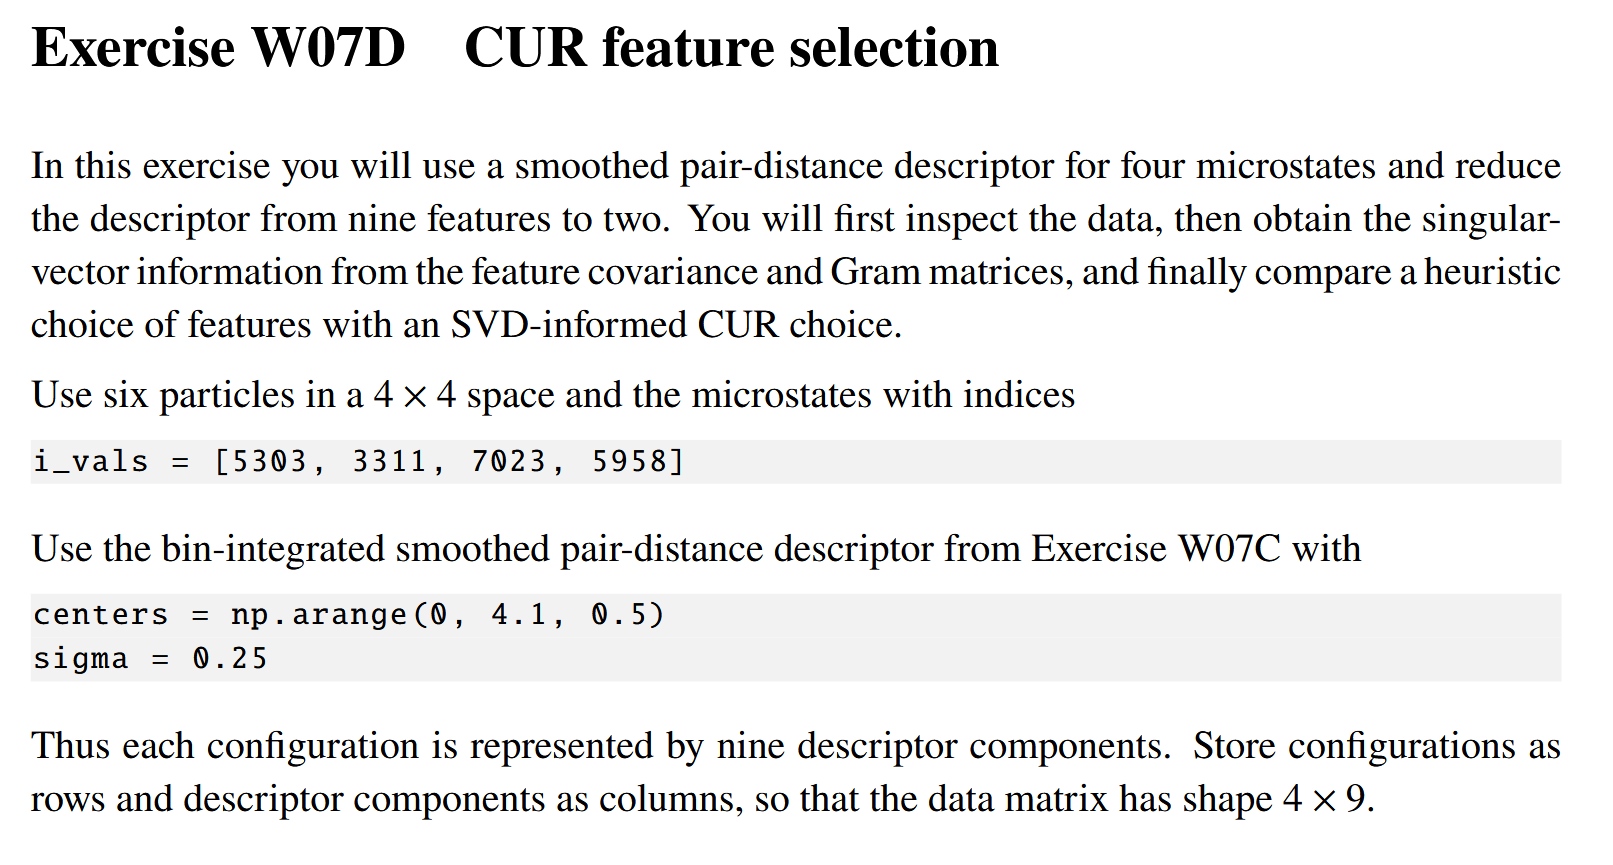
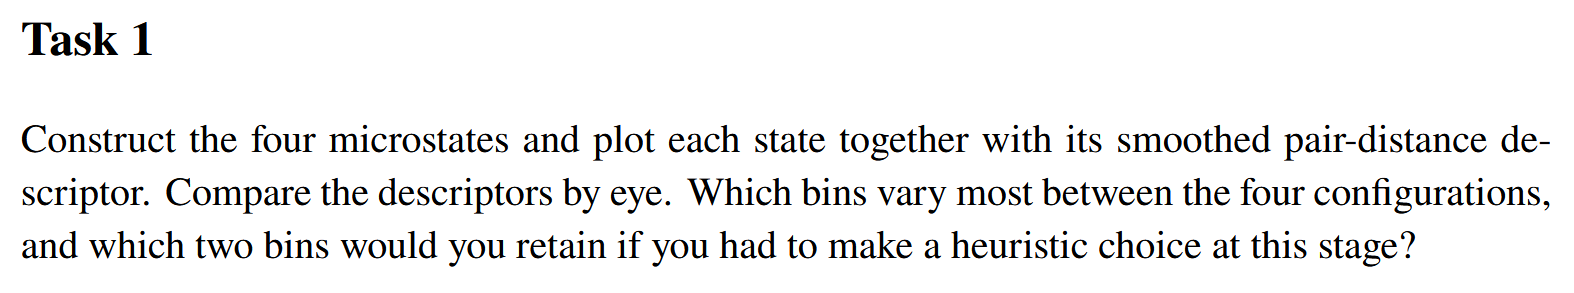

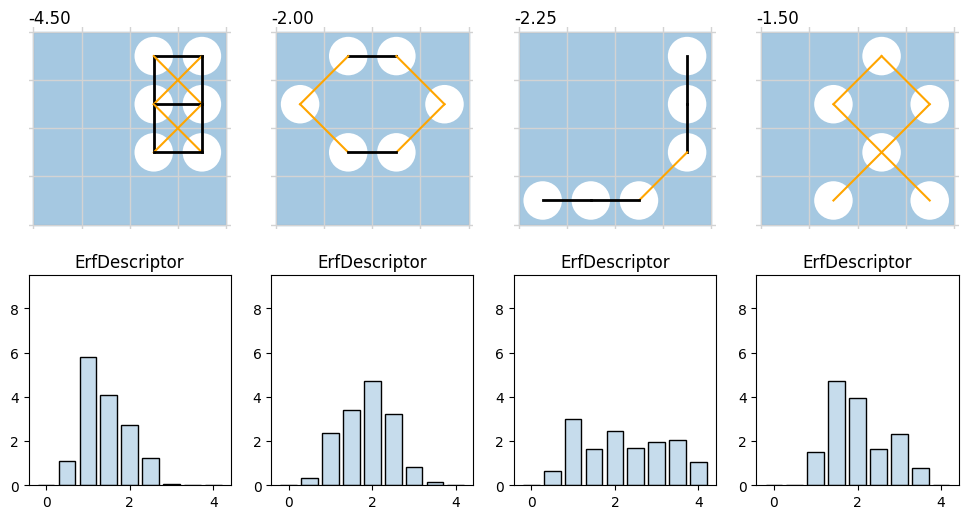

In [2]:
import numpy as np
import matplotlib.pyplot as plt 
from Pairdistance import * 
from week07 import *

class ErfDescriptor(ErfDescriptor):
    centers = np.arange(0, 4.1, 0.5)

desc = ErfDescriptor(sigma=0.25, dx=0.5)
MicroState = make_microstate_factory(N=6, L=4, descriptor_method=desc)
i_vals = [5303, 3311, 7023, 5958]

fig, ax = plt.subplots(2, 4, figsize=(12, 6))

for i, val in enumerate(i_vals):
    m = MicroState(val)
    m.plot(ax[0, i], label='Energy')
    m.plot_descriptor(ax[1, i])

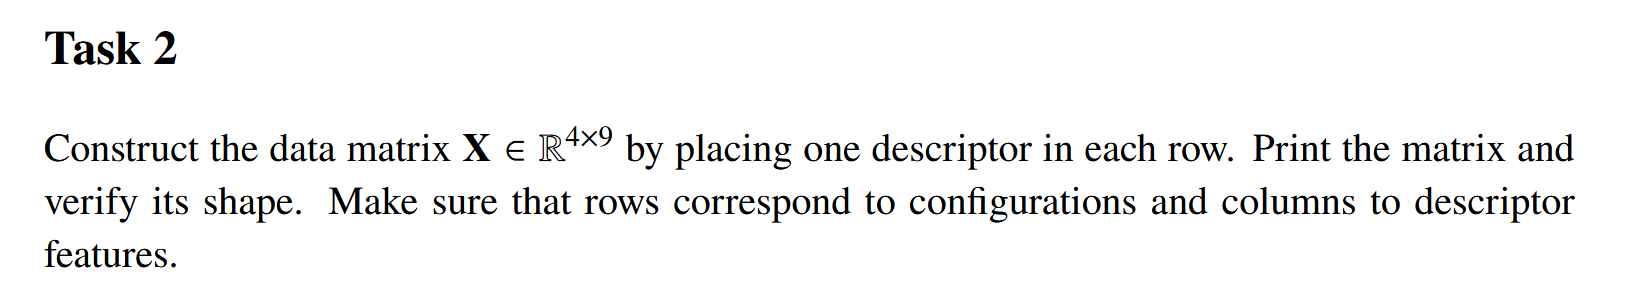

In [3]:
# Construct data matrix X (4 rows for configurations, 9 columns for features)
X = np.array([MicroState(i, descriptor_method=desc).descriptor for i in i_vals])

np.set_printoptions(precision=2, suppress=True)
print(f"Data Matrix X (shape: {X.shape}):\n", X)

Data Matrix X (shape: (4, 9)):
 [[0.01 1.12 5.79 4.09 2.72 1.23 0.04 0.   0.  ]
 [0.   0.33 2.38 3.4  4.7  3.22 0.8  0.16 0.  ]
 [0.01 0.63 2.99 1.65 2.46 1.7  1.95 2.06 1.06]
 [0.   0.02 1.52 4.72 3.97 1.62 2.34 0.8  0.02]]


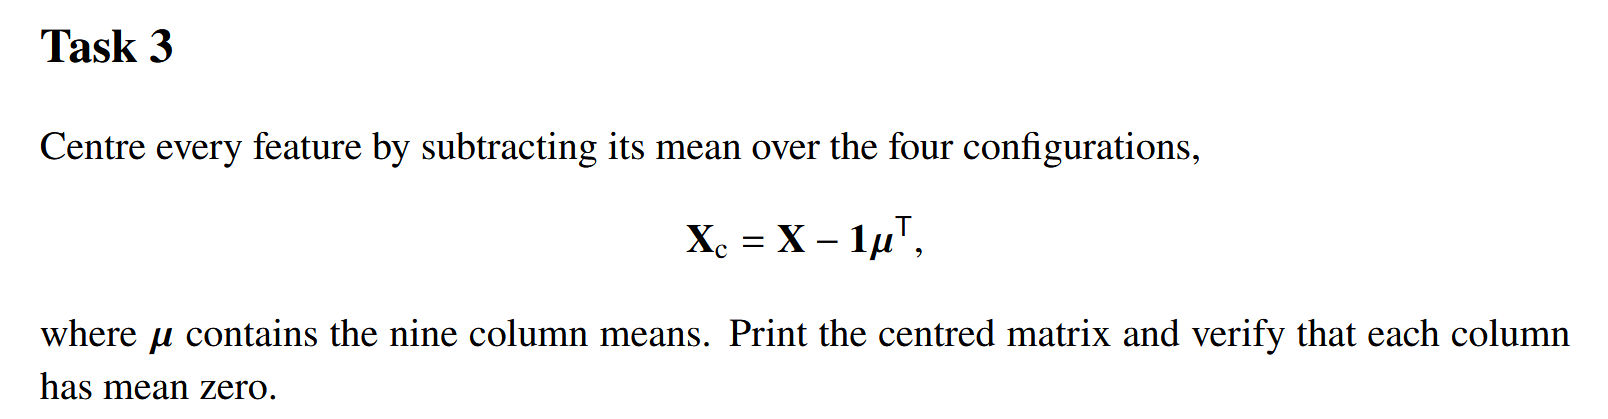

In [4]:
# Centre features by subtracting the mean of each column
mu = np.mean(X, axis=0)
Xc = X - mu

print(f"Centred Data Matrix Xc:\n", Xc)
print(f"\nXc Column means (should be 0):", np.mean(Xc, axis=0))

Centred Data Matrix Xc:
 [[ 0.01  0.59  2.62  0.62 -0.74 -0.71 -1.24 -0.75 -0.27]
 [-0.   -0.2  -0.79 -0.06  1.24  1.28 -0.48 -0.6  -0.27]
 [ 0.    0.11 -0.18 -1.81 -1.   -0.25  0.67  1.31  0.79]
 [-0.   -0.5  -1.65  1.25  0.5  -0.32  1.05  0.04 -0.25]]

Xc Column means (should be 0): [ 0. -0. -0. -0.  0.  0. -0.  0. -0.]


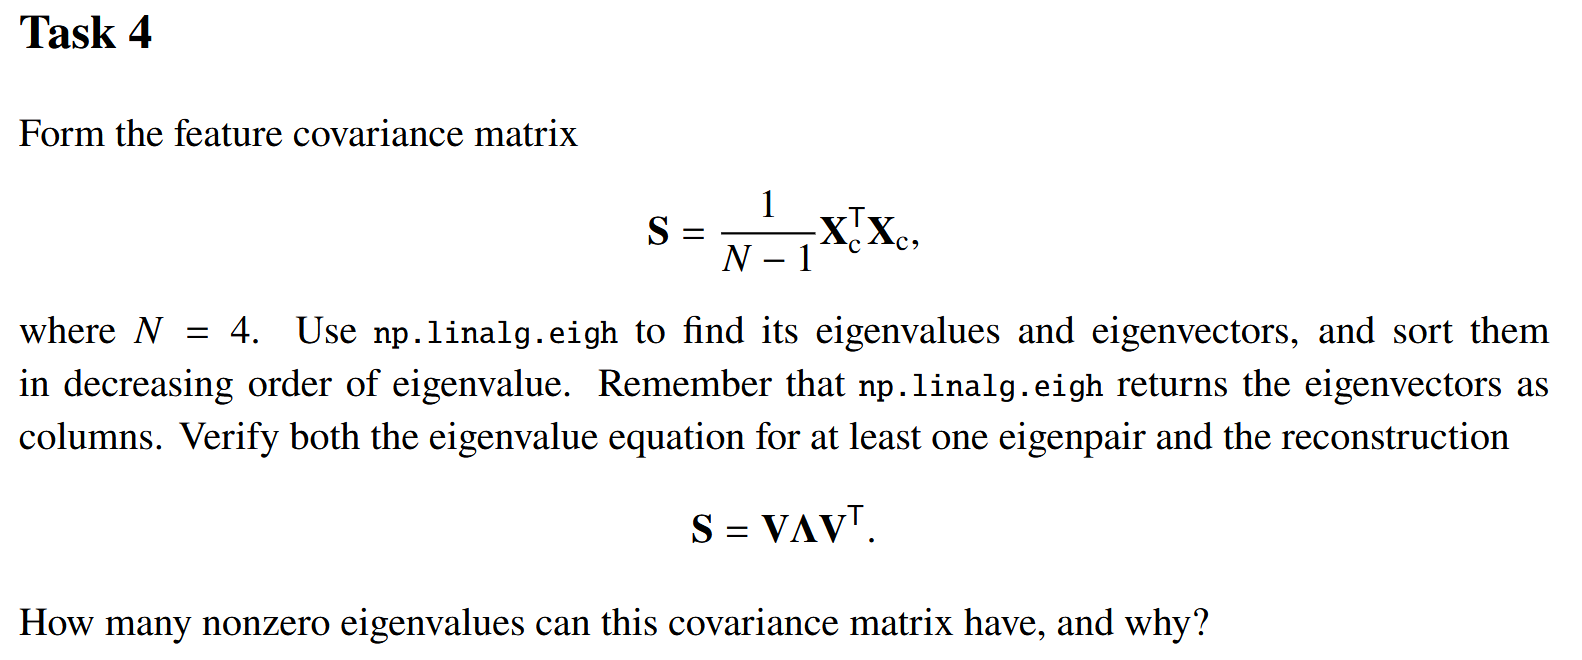

In [5]:
N = len(i_vals)
S = 1/(N-1) * Xc.T @ Xc

evals, evecs = np.linalg.eigh(S)

idx_S = np.argsort(evals)[::-1] # Sort decreasing[cite: 12]
lambda_S = evals[idx_S]
V = evecs[:, idx_S]

print("Eigenvalues of S:", lambda_S)

# Verify reconstruction S = V Lambda V^T
S_reconstructed = V @ np.diag(lambda_S) @ V.T
print("\nMax reconstruction error for S:", np.max(np.abs(S - S_reconstructed)))

Eigenvalues of S: [ 5.05  3.19  1.29  0.    0.    0.    0.   -0.   -0.  ]

Max reconstruction error for S: 4.440892098500626e-15


## Explanation for nonzero eigenvalues:
The data consists of N=4 configurations. After centering (subtracting the mean), 
the 4 points lie in a subspace of dimension at most N-1 = 3. 
Therefore, the rank of the covariance matrix S can be at most 3, resulting in 3 nonzero eigenvalues.

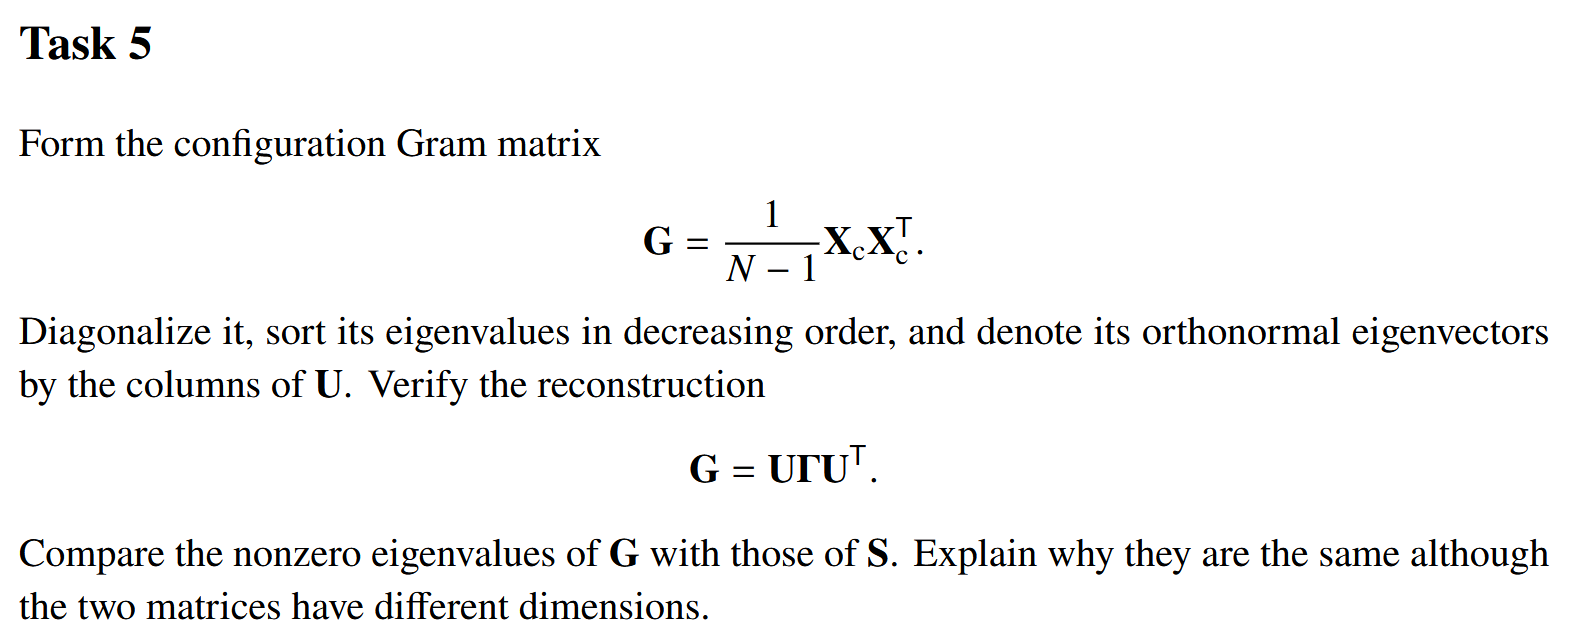

In [6]:
G = 1/(N-1) * Xc @ Xc.T

evals, evecs = np.linalg.eigh(G)

idx = np.argsort(evals)[::-1] 
L = evals[idx]
U = evecs[:, idx]

print("Eigenvalues of G:", L)

Eigenvalues of G: [5.05 3.19 1.29 0.  ]


## Explanation for identical eigenvalues:
S is proportional to Xc^T Xc and G is proportional to Xc Xc^T. 
In linear algebra, A^T A and A A^T always share the exact same nonzero eigenvalues, 
regardless of the matrix dimensions.

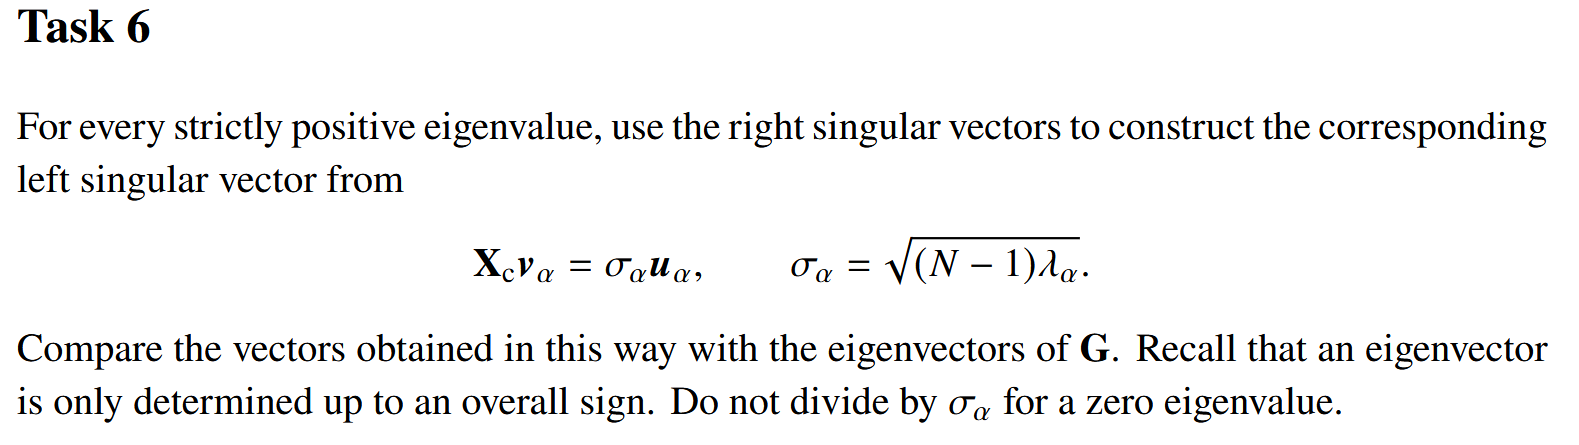

In [7]:
U_derived = np.zeros_like(U)
Sigma = np.zeros(N)

for alpha in range(N):
    if lambda_S[alpha] > 1e-10:  # Prevent division by zero[cite: 13]
        sigma_alpha = np.sqrt((N - 1) * lambda_S[alpha]) #[cite: 13]
        Sigma[alpha] = sigma_alpha
        # Reconstruct left singular vector: X_c v_alpha = sigma_alpha u_alpha
        U_derived[:, alpha] = (Xc @ V[:, alpha]) / sigma_alpha #[cite: 13]

print("U derived from V (columns correspond to singular vectors):\n", U_derived)
print("\nOriginal U from Gram matrix G:\n", U)

U derived from V (columns correspond to singular vectors):
 [[-0.83  0.21  0.16  0.  ]
 [ 0.26  0.38 -0.73  0.  ]
 [ 0.07 -0.86 -0.08  0.  ]
 [ 0.49  0.27  0.66  0.  ]]

Original U from Gram matrix G:
 [[-0.83  0.21  0.16  0.5 ]
 [ 0.26  0.38 -0.73  0.5 ]
 [ 0.07 -0.86 -0.08  0.5 ]
 [ 0.49  0.27  0.66  0.5 ]]


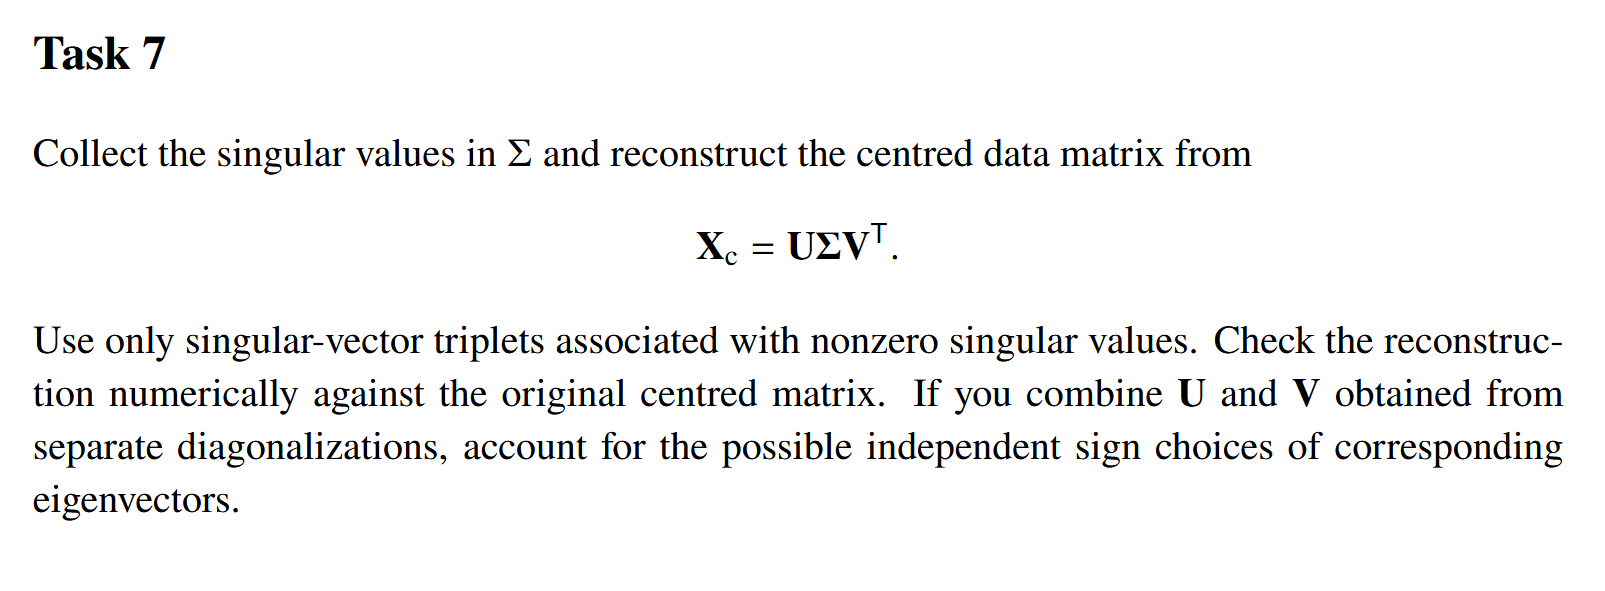

In [8]:
# Create the appropriately shaped Sigma matrix (4x9) to multiply with V^T
Sigma_matrix = np.zeros((N, Xc.shape[1]))
np.fill_diagonal(Sigma_matrix, Sigma)

# Reconstruct Xc = U Sigma V^T
# Note: Using U_derived to guarantee sign consistency with V
Xc_reconstructed = U_derived @ Sigma_matrix @ V.T 

print("Max reconstruction error for Xc:", np.max(np.abs(Xc - Xc_reconstructed)))

Max reconstruction error for Xc: 3.1086244689504383e-15


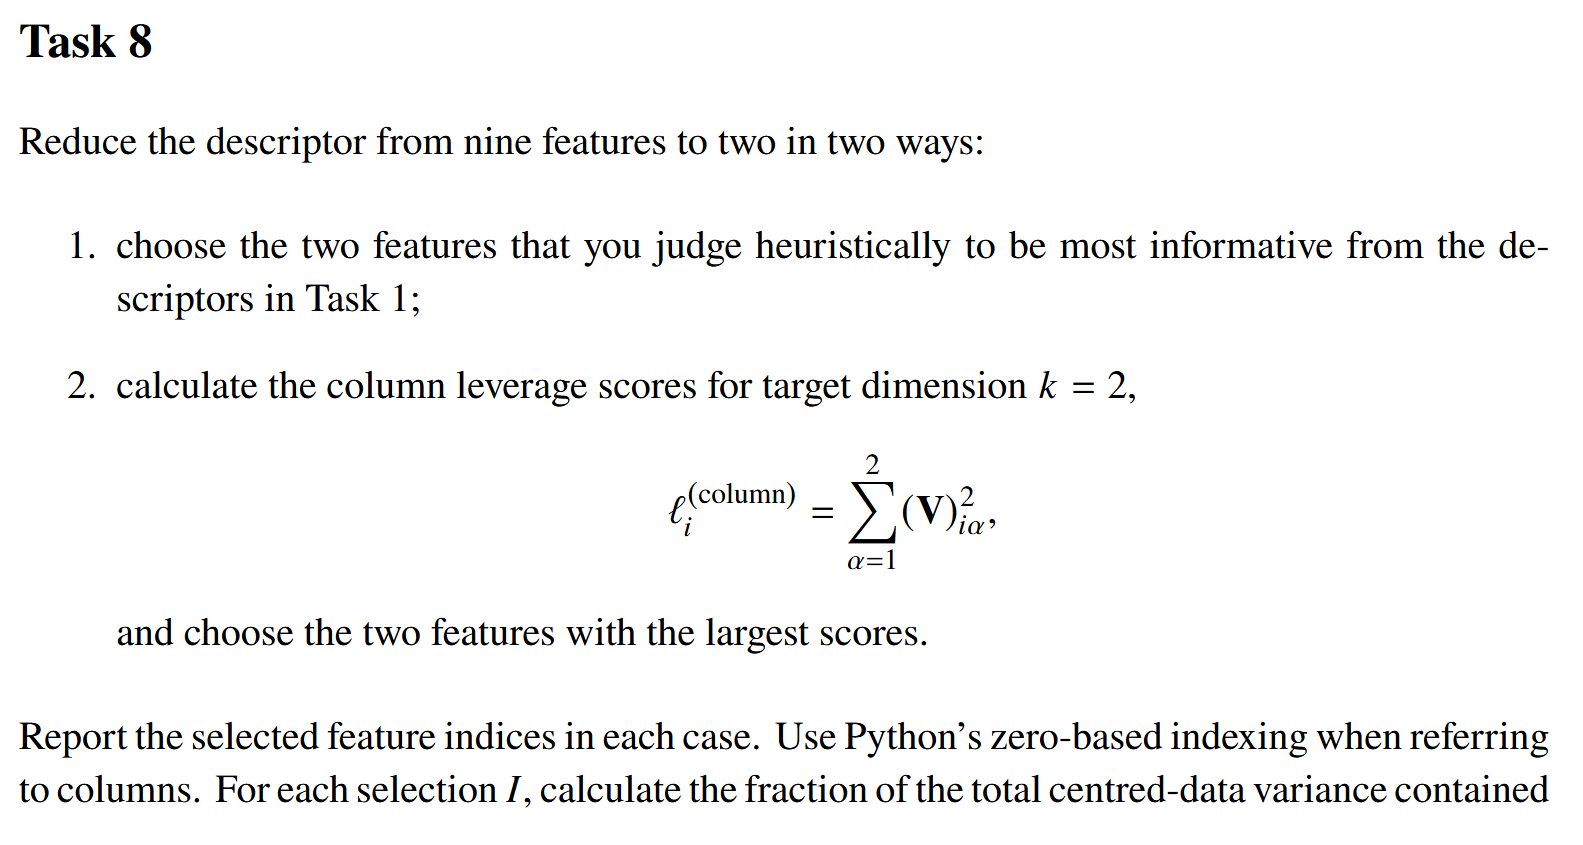
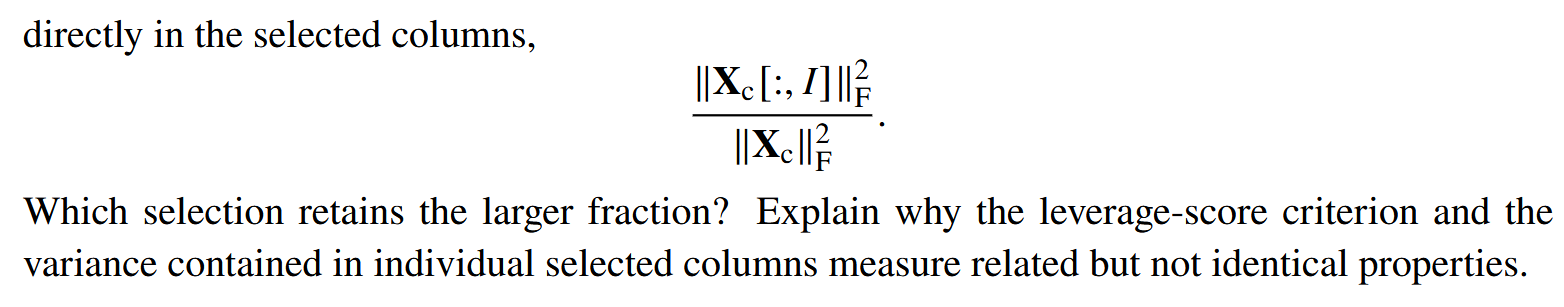

In [9]:
k = 2

# 1. Heuristic Choice
heuristic_idx = [1, 3] # Features corresponding to 1.0 and 2.0 pair distances

# 2. Leverage Score Choice
leverage_scores = np.sum(V[:, :k]**2, axis=1) 
cur_idx = np.argsort(leverage_scores)[::-1][:2]

print(f"Leverage Scores: \n{leverage_scores}")
print(f"Selected CUR feature indices: {cur_idx}")

# Calculate fraction of variance contained directly in the selected columns
total_variance = np.sum(np.var(Xc, axis=0))
var_heuristic = np.sum(np.var(Xc[:, heuristic_idx], axis=0)) / total_variance
var_cur = np.sum(np.var(Xc[:, cur_idx], axis=0)) / total_variance

print(f"\nVariance fraction retained (Heuristic): {var_heuristic:.3f}")
print(f"Variance fraction retained (CUR): {var_cur:.3f}")

Leverage Scores: 
[0.   0.04 0.68 0.42 0.26 0.06 0.2  0.26 0.09]
Selected CUR feature indices: [2 3]

Variance fraction retained (Heuristic): 0.206
Variance fraction retained (CUR): 0.542


## Explanation:
The individual variance measures the raw spread of a single feature. 
The leverage score evaluates how heavily a feature contributes to the leading principal components (the most structurally important directions). 
A feature might have high raw variance but be redundant, whereas leverage scores help identify structurally significant, non-redundant features.

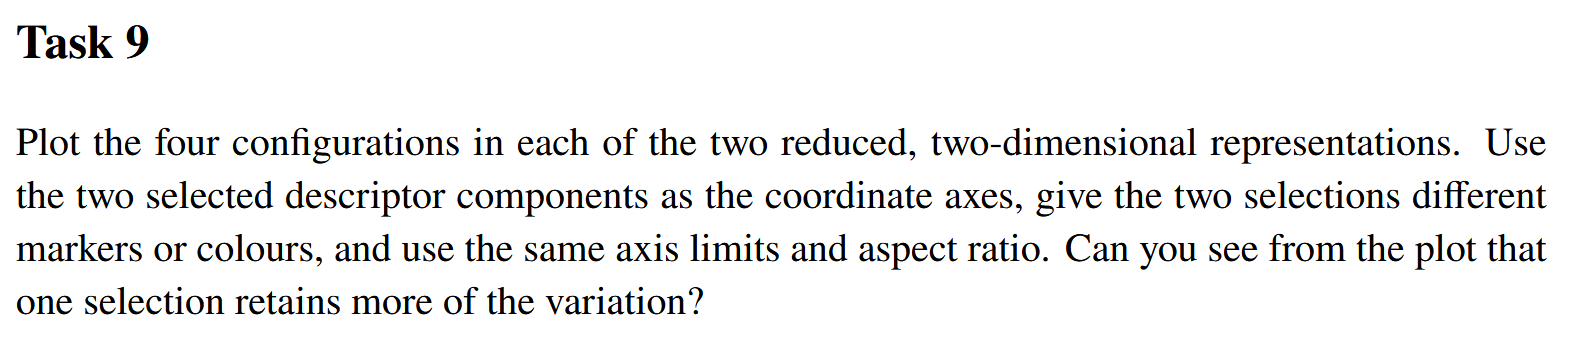

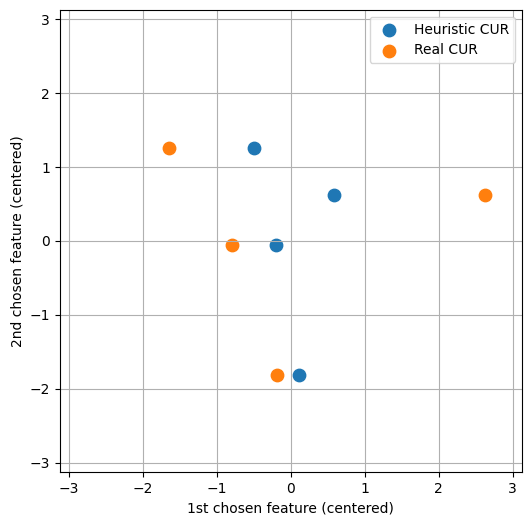

In [10]:
fig, ax = plt.subplots(figsize=(6, 6))

# Plot Heuristic coordinates
ax.scatter(Xc[:, heuristic_idx[0]], Xc[:, heuristic_idx[1]], 
           label='Heuristic CUR', s=80, marker='o')

# Plot Real CUR coordinates
ax.scatter(Xc[:, cur_idx[0]], Xc[:, cur_idx[1]], 
           label='Real CUR', s=80, marker='o')

# Force equal aspect ratio and limits[cite: 15]
limit = max(np.max(np.abs(Xc[:, heuristic_idx])), np.max(np.abs(Xc[:, cur_idx]))) + 0.5
ax.set_xlim(-limit, limit)
ax.set_ylim(-limit, limit)
ax.set_aspect('equal')

ax.set_xlabel('1st chosen feature (centered)')
ax.set_ylabel('2nd chosen feature (centered)')
ax.legend()
ax.grid(True)
plt.show()

## Visual analysis:
The Real CUR selection tends to spread the four configurations out more distinctly across the 2D space,
capturing a larger portion of the meaningful structural variation than the heuristic choice.